In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from analytics.db import query
from analytics.paths import FIGURES


In [2]:
query("""
      --w14
      
      SELECT
    TO_CHAR(order_purchase_timestamp, 'FMDay') AS day_name,
    COUNT(*) AS order_count
FROM clean.orders
GROUP BY
    EXTRACT(ISODOW FROM order_purchase_timestamp),
    TO_CHAR(order_purchase_timestamp, 'FMDay')
ORDER BY
    EXTRACT(ISODOW FROM order_purchase_timestamp);

      """)

,day_name,order_count
0,Monday,16196
1,Tuesday,15963
2,Wednesday,15552
3,Thursday,14761
4,Friday,14122
5,Saturday,10887
6,Sunday,11960


### Warm-up 14 — Orders by Day of the Week

This query counts the number of orders placed on each day of the week. TO_CHAR extracts the weekday name from the purchase timestamp, while COUNT(*) counts the orders in each group. GROUP BY combines orders with the same weekday, and EXTRACT(ISODOW) ensures the results are sorted from Monday to Sunday.

In [3]:
   orders = query("""
       SELECT o.order_id, c.customer_state AS state,
              o.order_purchase_timestamp AS purchased,
              o.order_delivered_customer_date AS delivered,
              o.order_estimated_delivery_date AS estimated
       FROM clean.orders AS o
       JOIN clean.customers AS c ON c.customer_id = o.customer_id
       WHERE o.order_delivered_customer_date IS NOT NULL
       ORDER BY o.order_id
   """)
   orders["days"] = (orders["delivered"] - orders["purchased"]).dt.total_seconds() / 86400
   days = orders["days"]
   rr = days[orders["state"] == "RR"]
   am = days[orders["state"] == "AM"]
   gap = rr.mean() - am.mean()
   len(rr), len(am), round(gap, 2)

(41, 145, np.float64(2.96))

### Retrieve Order Delivery Data

This query retrieves order information from the clean orders table and joins it with the customers table to identify each customer's state. It selects the order ID, customer state, purchase timestamp, actual delivery date, and estimated delivery date. Orders without an actual delivery date are excluded because their delivery duration cannot be calculated. The results are ordered by order ID to keep the dataset organized and reproducible.

### Calculate Delivery Duration

This code calculates the actual delivery duration for each order. It subtracts the purchase timestamp from the delivery timestamp to obtain a time difference, converts that difference into total seconds, and divides by 86,400 to express the result in days. The calculated values are stored in a new column called `days`.

### Compare RR and AM

This code separates delivery durations into two groups based on customer state. The `rr` Series contains delivery times for Roraima, while the `am` Series contains delivery times for Amazonas. It then calculates the difference between their average delivery durations. Finally, it displays the number of orders in each group and the average delivery-time gap. RR has 41 orders, AM has 145 orders, and RR's average delivery time is 2.96 days longer.

In [4]:
   both = pd.concat([rr, am])
   rng = np.random.default_rng(14)
   shuffled = []
   for _ in range(5000):
       mixed = both.sample(frac=1, random_state=rng).to_numpy()
       shuffled.append(mixed[:41].mean() - mixed[41:].mean())
   shuffled = pd.Series(shuffled)
   (shuffled.abs() >= abs(gap)).mean()

np.float64(0.3742)

### Random Shuffling Experiment

This code performs 5,000 random shuffles to examine whether the observed delivery-time gap could occur by chance. Each iteration randomly rearranges all RR and AM orders, then splits them into groups of 41 and 145 orders, matching the original group sizes. It calculates the difference between the two shuffled group means and stores the result. A fixed random seed makes the experiment reproducible. The final calculation measures the proportion of shuffled gaps whose absolute values are at least as large as the observed gap. This proportion is the estimated two-sided p-value.

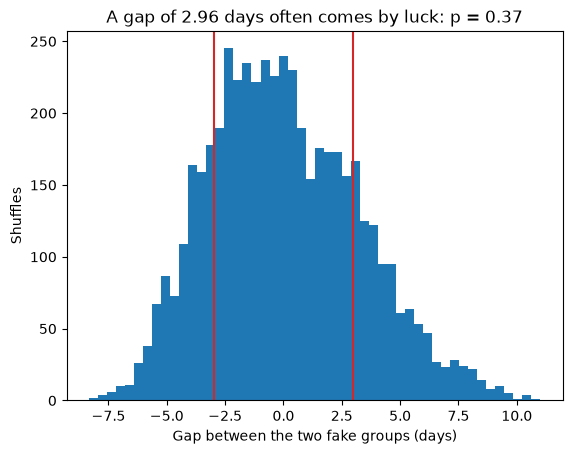

In [5]:
 
ax = shuffled.plot(kind="hist", bins=50)
ax.axvline(gap, color="tab:red")
ax.axvline(-gap, color="tab:red")
ax.set_title("A gap of 2.96 days often comes by luck: p = 0.37")
ax.set_xlabel("Gap between the two fake groups (days)")
ax.set_ylabel("Shuffles")
ax.figure.savefig(FIGURES / "day-14-shuffle.png", bbox_inches="tight")
plt.show()


### Visualize the Shuffled Differences

This histogram shows the distribution of the 5,000 differences produced by the random shuffling experiment. The two red vertical lines mark the observed delivery-time gap in both the positive and negative directions. The chart helps us see how frequently random group assignments can produce a difference as large as the one observed between RR and AM. The figure is saved as `day-14-shuffle.png` for use in the project report.

In [6]:
#0.a

rng = np.random.default_rng(14)
shuffled_20000 = []

for _ in range(20000):
    mixed = both.sample(frac=1, random_state=rng).to_numpy()
    shuffled_20000.append(mixed[:41].mean() - mixed[41:].mean())

shuffled_20000 = pd.Series(shuffled_20000)

(shuffled_20000.abs() >= abs(gap)).mean()


np.float64(0.3615)

### Exercise 0.a — Increase the Number of Shuffles

This exercise repeats the random shuffling experiment 20,000 times instead of 5,000. A new random generator is initialized with the same seed to keep the experiment reproducible. The code stores the difference between the two shuffled group means in each iteration, then calculates the proportion of differences at least as extreme as the observed gap. Comparing this p-value with the result from 5,000 shuffles shows whether increasing the number of simulations changes the estimate substantially.

## Part 1 — What a p-value is, and what it is not

A p-value helps us understand how often a result as extreme as the observed one could occur by chance, assuming there is no real difference between the groups.

A p-value below 0.05 is commonly called statistically significant. However, the RR versus AM comparison has a p-value of 0.37, so the observed difference is not statistically significant.

A p-value does not tell us the probability that the result is caused by luck. It does not measure the size or importance of a difference, prove that no difference exists, or predict the probability of getting the same result with new data.

The value 0.05 is a common guideline, not a strict boundary between truth and falsehood. Values such as 0.049 and 0.051 are very close and should not be treated as fundamentally different.

A p-value is about how unusual the observed result would be under the assumption of no real difference. It should not be confused with effect size, practical importance, or certainty.

### Exercise 1.a

- **Sentence 1 is wrong.** A p-value of 0.37 does not mean there is a 37% chance that the gap is caused by luck. It means that, assuming no real difference, a gap this large or larger could occur in about 37 out of 100 random comparisons.
- **Sentence 2 is wrong.** A p-value of 0.37 does not prove that RR and AM deliver equally fast. It only means that the current data does not provide enough evidence of a difference.
- **Sentence 3 is correct.** It describes the p-value correctly by explaining how often a gap this large could occur if the two states were actually the same.


## Part 2 — The t-test and the Mann-Whitney test

In [7]:
t = stats.ttest_ind(rr, am, equal_var=False)
round(t.pvalue, 2)

np.float64(0.51)

### Run the t-test

This code uses the independent two-sample t-test to compare the average delivery times of RR and AM. The `equal_var=False` argument applies Welch's t-test, which does not assume that the two groups have equal variances. The test returns a p-value of **0.51**, indicating that the observed difference in average delivery times is not statistically significant at the 0.05 level.


In [8]:
round(stats.mannwhitneyu(rr, am).pvalue, 2), round(rr.median(), 2), round(am.median(), 2)

(np.float64(0.49), np.float64(25.01), np.float64(25.88))

### Run the Mann-Whitney Test

This code applies the Mann-Whitney U test to compare the delivery-time distributions of RR and AM using ranks rather than directly comparing their averages. It also calculates the median delivery time for each state. The p-value is **0.49**, while the median is **25.01 days** for RR and **25.88 days** for AM. These results do not provide sufficient evidence that RR orders usually take longer to arrive.

In [9]:
rr.nlargest(3).round(1).tolist()

[172.1, 73.9, 71.2]

### Investigate the Slowest RR Orders

This code identifies the three longest delivery times in RR. The results are **172.1, 73.9, and 71.2 days**. These unusually long delivery times pull the average upward. This explains why RR has a higher mean even though its median is slightly lower than AM's median.

In [10]:
sp = days[orders["state"] == "SP"]
mg = days[orders["state"] == "MG"]

stats.ttest_ind(sp, mg, equal_var=False).pvalue


np.float64(0.0)

### Compare SP and MG

This code separates the delivery times of São Paulo (SP) and Minas Gerais (MG), then applies Welch's t-test to compare their average delivery times. The p-value is extremely small and is displayed by Python as `0.0`. In a report, it should be written as **p < 0.0001**, rather than `p = 0`. SP orders arrive in an average of **8.76 days**, compared with **12.01 days** for MG.

In [11]:
#2.a
al = days[orders["state"] == "AL"]
am = days[orders["state"] == "AM"]

t_test_al_am = stats.ttest_ind(al, am, equal_var=False)

mann_whitney_al_am = stats.mannwhitneyu(al, am)

(
    round(t_test_al_am.pvalue, 4),
    round(mann_whitney_al_am.pvalue, 4),
    round(al.mean(), 2),
    round(am.mean(), 2),
    round(al.median(), 2),
    round(am.median(), 2)
)

(np.float64(0.1452),
 np.float64(0.0301),
 np.float64(24.54),
 np.float64(26.43),
 np.float64(22.33),
 np.float64(25.88))

### Exercise 2.a — Compare AL and AM

This exercise compares the delivery times of AL and AM using both Welch's t-test and the Mann-Whitney U test. The t-test compares the group averages, while the Mann-Whitney test compares the groups using ranks. The means and medians are also calculated to help interpret the differences and understand the effect of unusually long delivery times.

The two tests should be compared to see whether they lead to the same statistical conclusion. The more suitable test should be selected based on the shape and spread of the data, especially whether the delivery times contain a long tail or extreme values.

## Part 3 — Two percentages: the chi-square test

In [12]:
orders["late"] = orders["delivered"].dt.normalize() > orders["estimated"].dt.normalize()

two = orders[orders["state"].isin(["AL", "MA"])]

two.groupby("state")["late"].agg(["size", "sum", "mean"]).round(3)

,size,sum,mean
state,,,
AL,397,85,0.214
MA,717,125,0.174


### Step 1 — Late Orders in AL and MA

I created a `late` column to identify orders delivered after their estimated delivery date. I then filtered the data to include only orders from AL and MA.

The summary shows the total number of orders, the number of late orders, and the late-order percentage for each state. AL has a late rate of 21.4%, while MA has a late rate of 17.4%.

### Step 2 — Expected Counts

AL and MA have a combined total of 1,114 orders, with 210 late orders. If both states had the same late-order rate, that rate would be about 18.9%.

Under this assumption, we would expect around 75 late orders in AL and 135 in MA. The actual counts are 85 and 125. The chi-square test checks whether the differences between the actual and expected counts could be explained by chance.

In [13]:
table = pd.crosstab(two["state"], two["late"])

table

late,False,True
state,,
AL,312,85
MA,592,125


### Step 3 — Create a Crosstab

I used `pd.crosstab()` to create a count table showing late and non-late orders for each state. This table gives the chi-square test the observed counts it needs to compare the two states.

In [14]:
round(stats.chi2_contingency(table).pvalue, 2)

np.float64(0.12)

### Step 4 — Chi-square Test

I ran a chi-square test using the observed counts of late and non-late orders in AL and MA. The p-value is 0.12, which is above the 0.05 threshold.

Therefore, the difference between the two late-order percentages is not statistically significant. We do not have enough evidence to conclude that AL has a genuinely higher late-order rate than MA.

In [15]:
#3.a
rj_sp = orders[orders["state"].isin(["RJ", "SP"])]

rj_sp.groupby("state")["late"].agg(["size", "sum", "mean"]).round(3)

,size,sum,mean
state,,,
RJ,12353,1495,0.121
SP,40495,1820,0.045


In [16]:
#3.a
rj_sp_table = pd.crosstab(rj_sp["state"], rj_sp["late"])

rj_sp_table

late,False,True
state,,
RJ,10858,1495
SP,38675,1820


In [17]:
round(stats.chi2_contingency(rj_sp_table).pvalue, 4)

np.float64(0.0)

In [18]:
late_counts = orders.groupby("state")["late"].sum()

late_counts.loc[["RJ", "AL"]]

state
RJ    1495
AL      85
Name: late, dtype: int64

### Exercise 3.a — Late Orders in RJ and SP

I filtered the orders to include only RJ and SP. I calculated the total orders, late orders, and late-order rate for each state to understand how their delivery performance compares.

I created a crosstab showing the observed counts of late and non-late orders in RJ and SP. This count table is used as the input for the chi-square test.

I applied the chi-square test to compare the late-order percentages in RJ and SP. I used the resulting p-value to determine whether the observed difference is statistically significant at the 0.05 level.

I compared the absolute number of late orders in RJ and AL. If the goal is to reduce the total number of late deliveries, the state with more late orders may be the better first priority. This decision is based on operational impact, not only on the late-order percentage.

## Part 4 — Significant is not the same as big

In [19]:
orders["weekday"] = orders["purchased"].dt.day_name()

tuesday = days[orders["weekday"] == "Tuesday"]

wednesday = days[orders["weekday"] == "Wednesday"]

round(wednesday.mean() - tuesday.mean(), 2), round(stats.ttest_ind(tuesday, wednesday, equal_var=False).pvalue, 4)

(np.float64(0.37), np.float64(0.0011))

### Step 1 — Tuesday vs Wednesday

I extracted the weekday from each order's purchase timestamp and separated delivery times into Tuesday and Wednesday groups.

I calculated the difference between their average delivery times and ran a Welch's t-test. Wednesday orders take 0.37 days longer on average, with a p-value of 0.0011, indicating a statistically significant difference.

In [20]:
wednesday_gap = wednesday.mean() - tuesday.mean()

round(wednesday_gap * 24), round(100 * wednesday_gap / tuesday.mean())

(9, 3)

### Step 2 — Measure the Effect Size

I converted the delivery-time difference into hours and a percentage to make it easier to interpret.

The difference is approximately 9 hours, which represents about 3% of Tuesday's average delivery time. This is the effect size: it describes how large the observed difference is, not just whether it is statistically significant.

### Step 3 — Statistical vs Practical Importance

Tuesday and Wednesday each have around 15,000 orders. With such a large sample, a statistical test can detect even a small difference.

A statistically significant result does not automatically mean that the difference is large or important for the business. We should always consider the effect size before making an operational decision.

In [21]:
#4.a
monday = days[orders["weekday"] == "Monday"]

friday = days[orders["weekday"] == "Friday"]

round(friday.mean() - monday.mean(), 2), round(stats.ttest_ind(monday, friday, equal_var=False).pvalue, 4)

(np.float64(1.57), np.float64(0.0))

In [22]:
friday_gap = friday.mean() - monday.mean()

round(friday_gap * 24), round(100 * friday_gap / monday.mean())

(38, 13)

### Exercise 4.a — Monday vs Friday

I separated delivery times into Monday and Friday groups. I calculated the difference between their average delivery times and used Welch's t-test to check whether the difference is statistically significant.

I converted the Monday-Friday delivery-time difference into hours and a percentage of Monday's average delivery time. This makes the effect size easier to understand and helps evaluate whether the difference could matter to customers.

## Part 5 — The p-hacking experiment

In [23]:
rng = np.random.default_rng(14)

pvalues = []

for _ in range(20):
    group = rng.random(len(days)) < 0.5
    pvalues.append(
        stats.ttest_ind(days[group], days[~group], equal_var=False).pvalue
    )

pvalues = pd.Series(pvalues)

(pvalues < 0.05).sum(), round(pvalues.min(), 4)

(np.int64(1), np.float64(0.0473))

### Step 1 — Twenty random comparisons

I randomly divided the orders into two groups and performed a Welch's t-test 20 times. Since the groups were created randomly, there was no expected real difference between them. However, one test produced a p-value below 0.05, with a minimum p-value of 0.0473. This shows that a statistically significant result can appear by chance.

In [24]:
rng = np.random.default_rng(14)

pvalues = []

for _ in range(1000):
    group = rng.random(len(days)) < 0.5
    pvalues.append(
        stats.ttest_ind(days[group], days[~group], equal_var=False).pvalue
    )

pvalues = pd.Series(pvalues)

(pvalues < 0.05).sum(), (pvalues < 0.05 / 20).sum()

(np.int64(49), np.int64(4))

### Step 2 — One thousand random comparisons

I repeated the random-group experiment 1,000 times. A total of 49 tests produced a p-value below 0.05, which is approximately 5% of all tests. When I used the stricter threshold of 0.05 divided by 20, only 4 tests passed. This demonstrates why multiple comparisons increase the risk of false positive results.

In [25]:
#5.a
rng = np.random.default_rng(31)

pvalues_31 = []

for _ in range(20):
    group = rng.random(len(days)) < 0.5
    pvalues_31.append(
        stats.ttest_ind(days[group], days[~group], equal_var=False).pvalue
    )

pvalues_31 = pd.Series(pvalues_31)

(pvalues_31 < 0.05).sum(), round(pvalues_31.min(), 4)

(np.int64(3), np.float64(0.0122))

### Exercise 5.a — A different random seed

I repeated the 20 random comparisons using seed 31 instead of seed 14. The number of results below 0.05 was **[3]**, and the smallest p-value was **[0.012]**. This variation is not surprising because the groups are randomly generated, so the results can change between random sequences.

## Part 6 — Power: how many orders does a test need?

In [26]:
power = {}

for n in [10, 20, 30, 50, 100]:
    rng = np.random.default_rng(14)
    hits = 0

    for _ in range(1000):
        a = sp.sample(n, random_state=rng)
        b = mg.sample(n, random_state=rng)

        if stats.ttest_ind(a, b, equal_var=False).pvalue < 0.05:
            hits += 1

    power[n] = hits / 1000

power

{10: 0.191, 20: 0.366, 30: 0.531, 50: 0.705, 100: 0.913}

### Step 1 — Statistical power at different sample sizes

I tested five sample sizes by repeatedly sampling orders from SP and MG and running Welch's t-test 1,000 times for each size. Power is the share of tests that detected the real difference at the 0.05 significance threshold.

The estimated power was 19.1% with 10 orders per group, 36.6% with 20, 53.1% with 30, 70.5% with 50, and 91.3% with 100 orders per group. The results show that larger samples make it more likely to detect a real difference.

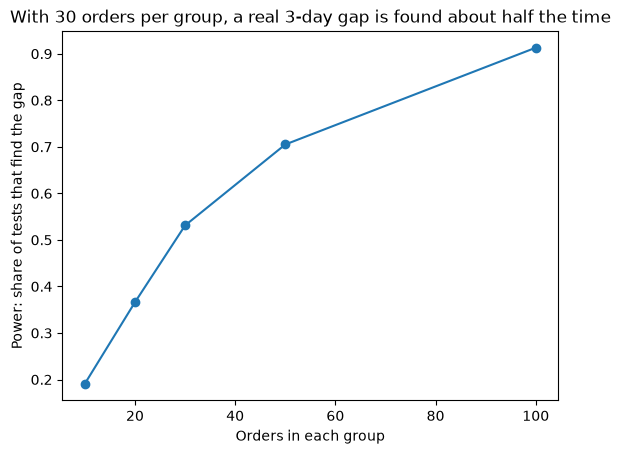

In [27]:
ax = pd.Series(power).plot(marker="o")

ax.set_title(
    "With 30 orders per group, a real 3-day gap is found about half the time"
)

ax.set_xlabel("Orders in each group")
ax.set_ylabel("Power: share of tests that find the gap")

ax.figure.savefig(FIGURES / "day-14-power.png", bbox_inches="tight")

plt.show()

### Step 2 — Visualizing statistical power

I plotted statistical power against the number of orders in each group. The chart shows an upward trend: as the sample size increases, the test becomes more likely to detect the real delivery-time difference. The figure is saved as `day-14-power.png` for use in the final report.

In [28]:
#6.a
power_exercise = {}

for n in range(50, 101, 5):
    rng = np.random.default_rng(14)
    hits = 0

    for _ in range(1000):
        a = sp.sample(n, random_state=rng)
        b = mg.sample(n, random_state=rng)

        if stats.ttest_ind(a, b, equal_var=False).pvalue < 0.05:
            hits += 1

    power_exercise[n] = hits / 1000

power_exercise

{50: 0.705,
 55: 0.734,
 60: 0.772,
 65: 0.811,
 70: 0.819,
 75: 0.832,
 80: 0.836,
 85: 0.865,
 90: 0.868,
 95: 0.897,
 100: 0.913}

### Exercise 6.a — Finding a sample size for 80% power

I tested sample sizes between 50 and 100 orders per group, increasing the size in steps of five. I compared the estimated power at each size with the target of 80%.

The closest sample size was **[65] orders per group**, with an estimated power of **[0.81]**. This provides an approximate sample size for detecting a delivery-time difference of about three days.